# Qafila Lakehouse · Full project walkthrough

**Team:** Yahya Mohammed Khuzaimi · Abdullah Bin Ghafrah · **Course:** Modern Data Engineering, SDAIA Academy

This notebook builds the whole platform in code cells, one decision at a time. Choose **Run all** to see it end to end. All data is synthetic.

| Part | What you build | Rubric |
|---|---|---|
| 1 | Setup | Reproducibility |
| 2 | Ingestion: vault, snapshots, API, events, files | Pipeline |
| 3 | The payments contract | Quality |
| 4 | dbt: staging, quarantine, marts | Modeling, quality |
| 5 | Governance: views, catalog, PII scan | Governance |
| 6 | Publishing gold tables to Iceberg | Pipeline |
| 7 | Dagster: one graph, a schedule, checks | Orchestration |
| 8 | Proofs: safe re-runs, a blocked feed | Quality, pipeline |
| 9 | What the business gets | Presentation |

The same code lives in `labs/capstone/` for the one-command run. This notebook explains it; the repository is the official submission.

## 1 · Setup

On Colab, this clones the repository and installs the tools. Everything we create goes into one folder, so a reset is a single delete.

In [1]:
import contextlib, hashlib, hmac, io, json, os, random, re, secrets, shutil, subprocess, sys, time, warnings
from datetime import datetime, timezone
from pathlib import Path

REPO_URL = "https://github.com/vxji/data-engineering.git"
COURSE_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
ROOT = Path("/content/data-engineering")
ZIP = Path("/content/qafila-lakehouse-upload.zip")    # optional: upload it to Colab's Files panel


def clone(url):
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    return subprocess.run(["git", "clone", "-q", url, str(ROOT)], env=env).returncode == 0


if "google.colab" in sys.modules:
    if not (ROOT / "labs/capstone/ingest/incremental.py").exists():
        shutil.rmtree(ROOT, ignore_errors=True)
        if not clone(REPO_URL):
            print("Your repository isn't reachable, so using the course repository plus the uploaded zip.")
            shutil.rmtree(ROOT, ignore_errors=True)
            if not clone(COURSE_URL):
                raise RuntimeError("Could not clone the course repository. Check the runtime's internet access.")
        if ZIP.exists():
            shutil.unpack_archive(ZIP, ROOT)
        if not (ROOT / "labs/capstone/ingest/incremental.py").exists():
            raise FileNotFoundError("Project files not found. Upload qafila-lakehouse-upload.zip to /content, or publish them to your public fork.")
    os.chdir(ROOT / "labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

import dagster as dg
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml
from dagster_dbt import DbtCliResource, dbt_assets

import de_utils as U

U.ensure_data()
print("data:", U.RAW)

Your repository isn't reachable, so using the course repository plus the uploaded zip.
data: /content/data-engineering/labs/data/raw


In [2]:
HOME = U.ARTIFACTS / "walkthrough"
shutil.rmtree(HOME, ignore_errors=True)
HOME.mkdir(parents=True)

DB = HOME / "qafila.duckdb"            # the warehouse
VAULT = HOME / "vault.duckdb"          # identifiers only, a separate file
LAKE = HOME / "lakehouse"              # Iceberg gold tables
SECRETS = HOME / ".secrets"            # git ignores everything under artifacts/
CAPSTONE = Path("capstone")
DBT_DIR = CAPSTONE / "dbt_project"
RAW = U.RAW.as_posix()
os.environ["QAFILA_DUCKDB"] = DB.resolve().as_posix()      # dbt's profiles.yml reads this


def connect(path=DB):
    con = duckdb.connect(str(path))
    with contextlib.suppress(duckdb.Error):       # the setting needs ipywidgets in a notebook
        con.execute("SET enable_progress_bar = false")
    return con


def sql(query, params=None, path=DB):
    con = connect(path)
    try:
        return con.execute(query, params or []).fetchall()
    finally:
        con.close()


def df(query, path=DB):
    con = connect(path)
    try:
        return con.execute(query).df()
    finally:
        con.close()


def now_utc():
    return datetime.now(timezone.utc).replace(tzinfo=None)


print("everything goes to", HOME)

everything goes to /content/data-engineering/labs/artifacts/walkthrough


## 2 · Ingestion

Five sources, three strategies:

| Source | Type | Strategy | Why |
|---|---|---|---|
| Customers | Database | Full snapshot, split at the boundary | A snapshot notices deletes; identifiers never enter the warehouse |
| Orders, lines, products, stores | Database | Full snapshot | Small tables, simplest correct option |
| Payments | HTTP API | **Incremental upsert** | Rows change: refunds update old payments |
| Courier events | Events | **Incremental append** | Every delivery of an event is new |
| Supplier prices, reviews | Files | Full reload | Small files, replaced as a whole |

### 2.1 · The vault: identifiers leave at the boundary

If identifiers never enter the warehouse, no later model, view or backup can leak them. A plain hash isn't enough, because anyone with a list of national IDs can hash them and match. A keyed hash (HMAC) needs a secret key.

Tokens are still personal data under PDPL: whoever holds the key can match them.

In [3]:
def pseudo_key():
    """The key comes from the environment. Otherwise a random one is created once, outside git."""
    env = os.environ.get("QAFILA_PSEUDO_KEY")
    if env:
        return env.encode()
    path = SECRETS / "pseudo_key"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(secrets.token_hex(32), encoding="utf-8")
        path.chmod(0o600)
    return path.read_text(encoding="utf-8").strip().encode()


def pseudonymize(value, key):
    return hmac.new(key, value.encode(), hashlib.sha256).hexdigest()[:20]


def load_customers():
    """Identifiers go to the vault. The warehouse gets a token and safe columns."""
    key = pseudo_key()
    con = connect()
    try:
        con.execute("CREATE SCHEMA IF NOT EXISTS raw")
        con.execute("INSTALL sqlite; LOAD sqlite;")
        con.execute(f"ATTACH '{RAW}/qafila_oltp.sqlite' AS app (TYPE sqlite, READ_ONLY)")
        customers = con.execute("SELECT * FROM app.customers").df()
        customers["person_token"] = customers["national_id"].map(lambda v: pseudonymize(v, key) if isinstance(v, str) else None)
        customers["email_domain"] = customers["email"].str.strip().str.lower().str.split("@").str[-1]
        safe = customers[["customer_id", "person_token", "email_domain", "city", "district", "created_at", "updated_at", "is_deleted"]]
        con.register("safe", safe)
        con.execute("CREATE OR REPLACE TABLE raw.customers AS SELECT *, now()::TIMESTAMP AS _loaded_at FROM safe")
    finally:
        con.close()
    vault = connect(VAULT)
    try:
        identifiers = customers[["customer_id", "person_token", "full_name", "email", "mobile", "national_id", "iban"]]
        vault.register("identifiers", identifiers)
        vault.execute("CREATE OR REPLACE TABLE customers_pii AS SELECT * FROM identifiers")
        vault.execute("""CREATE OR REPLACE MACRO mask_mobile(m) AS
                         CASE WHEN m IS NULL THEN NULL ELSE '+9665*****' || right(regexp_replace(m, '\\D', '', 'g'), 2) END""")
        vault.execute("CREATE SCHEMA IF NOT EXISTS support")
        vault.execute("""CREATE OR REPLACE VIEW support.customers AS
                         SELECT customer_id, full_name, email, mask_mobile(mobile) AS mobile FROM customers_pii""")
    finally:
        vault.close()
    return {"rows": len(customers), "people": int(customers["person_token"].nunique())}


print(load_customers())
print("raw.customers columns:", df("DESCRIBE raw.customers").column_name.tolist())

{'rows': 7442, 'people': 7384}
raw.customers columns: ['customer_id', 'person_token', 'email_domain', 'city', 'district', 'created_at', 'updated_at', 'is_deleted', '_loaded_at']


**Result:** 7,442 accounts belong to 7,384 people, so 58 people have two accounts, and we found that without seeing an ID. The warehouse table holds no name, national ID, IBAN, email or mobile.

### 2.2 · Snapshots and files

In [4]:
SNAPSHOT_TABLES = ["stores", "products", "orders", "order_items"]
FILE_SOURCES = {
    "supplier_prices": f"read_csv('{RAW}/suppliers/*.csv', union_by_name=true, all_varchar=true, filename=true)",
    "reviews": f"read_csv('{RAW}/reviews.csv')",
}


def load_snapshot(table):
    con = connect()
    try:
        con.execute("CREATE SCHEMA IF NOT EXISTS raw")
        con.execute("INSTALL sqlite; LOAD sqlite;")
        con.execute(f"ATTACH '{RAW}/qafila_oltp.sqlite' AS app (TYPE sqlite, READ_ONLY)")
        con.execute(f"CREATE OR REPLACE TABLE raw.{table} AS SELECT *, now()::TIMESTAMP AS _loaded_at FROM app.{table}")
        return con.execute(f"SELECT count(*) FROM raw.{table}").fetchall()[0][0]
    finally:
        con.close()


def load_file(table):
    sql("CREATE SCHEMA IF NOT EXISTS raw")
    sql(f"CREATE OR REPLACE TABLE raw.{table} AS SELECT * FROM {FILE_SOURCES[table]}")
    return sql(f"SELECT count(*) FROM raw.{table}")[0][0]


print({t: load_snapshot(t) for t in SNAPSHOT_TABLES})
print({t: load_file(t) for t in FILE_SOURCES})

{'stores': 12, 'products': 356, 'orders': 45766, 'order_items': 172545}
{'supplier_prices': 640, 'reviews': 3000}


### 2.3 · State: where each load stopped

A **cursor** says how far a load got. We keep it in the warehouse, and every load also writes one row to a log, which is how we can answer "what did last night's run change?"

In [5]:
PAYMENT_COLS = ["payment_id", "order_id", "amount", "currency", "method", "status", "card_last4",
                "wallet_provider", "created_at", "updated_at"]
PAYMENTS_START = "2026-08-01T00:00:00.000Z"
EVENTS_START = "2026-01-01T00:00:00.000Z"


def ensure_ops(con):
    con.execute("CREATE SCHEMA IF NOT EXISTS raw")
    con.execute("CREATE SCHEMA IF NOT EXISTS ops")
    con.execute("CREATE TABLE IF NOT EXISTS ops.ingest_state (source VARCHAR PRIMARY KEY, cursor VARCHAR, updated_at TIMESTAMP)")
    con.execute("""CREATE TABLE IF NOT EXISTS ops.ingest_log (
        logged_at TIMESTAMP, source VARCHAR, as_of VARCHAR, cursor_before VARCHAR, cursor_after VARCHAR,
        rows_fetched BIGINT, rows_new BIGINT, rows_updated BIGINT, rows_unchanged BIGINT, requests BIGINT, throttled BIGINT)""")


def read_cursor(con, source, default):
    rows = con.execute("SELECT cursor FROM ops.ingest_state WHERE source = ?", [source]).fetchall()
    return rows[0][0] if rows else default


def write_cursor(con, source, cursor):
    con.execute("DELETE FROM ops.ingest_state WHERE source = ?", [source])
    con.execute("INSERT INTO ops.ingest_state VALUES (?, ?, ?)", [source, cursor, now_utc()])

### 2.4 · Payments: incremental upsert from an API

The provider sends pages, and it rate-limits us. So we follow `next_page`, and on a 429 or a 5xx we wait and retry, with a little randomness so that many clients don't return together. A 400 or 404 won't get better, so it raises.

The cursor is **inclusive**: two rows can share a timestamp, and a strict `>` could skip the second. The newest row returns every run, and the key makes that harmless.

The rows and the cursor commit in **one transaction**. If the job dies before `COMMIT`, both stay as they were, and the next run fetches the same rows.

In [6]:
def get_with_retry(url, params, tries=6, timeout=10):
    for attempt in range(tries):
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 429 or r.status_code >= 500:
            wait = float(r.headers.get("Retry-After", 2 ** attempt))
            time.sleep(wait + random.uniform(0, 0.25))
            continue
        r.raise_for_status()
        return r.json()
    raise RuntimeError(f"gave up after {tries} tries: {url}")


def fetch_payments(since, clock):
    api = U.PaymentsAPI(page_size=500, rate_limit_every=25, clock=clock)
    base = api.start()
    try:
        rows, page = [], 1
        while page:
            body = get_with_retry(f"{base}/payments", {"updated_since": since, "page": page})
            rows += body["data"]
            page = body["next_page"]
        return rows, api.requests, api.throttled
    finally:
        api.stop()


def load_payments(clock=None, fault=None):
    con = connect()
    try:
        ensure_ops(con)
        con.execute("""CREATE TABLE IF NOT EXISTS raw.payments (
            payment_id VARCHAR, order_id BIGINT, amount DOUBLE, currency VARCHAR, method VARCHAR, status VARCHAR,
            card_last4 VARCHAR, wallet_provider VARCHAR, created_at VARCHAR, updated_at VARCHAR, _loaded_at TIMESTAMP)""")
        since = read_cursor(con, "payments", PAYMENTS_START)
        rows, made, throttled = fetch_payments(since, clock)
        if not rows:
            return {"fetched": 0, "new": 0, "updated": 0, "unchanged": 0}
        if fault == "bad-status":                 # demo only: the provider sends a status nobody agreed
            rows[0]["status"] = "refund_pending"
        unknown = sorted(set().union(*rows) - set(PAYMENT_COLS))
        batch = pd.DataFrame(rows).reindex(columns=PAYMENT_COLS)
        batch["card_last4"] = batch["card_last4"].astype("string")
        batch["wallet_provider"] = batch["wallet_provider"].astype("string")
        new_cursor = max(r["updated_at"] for r in rows)
        con.register("batch", batch)
        new, updated, unchanged = con.execute("""
            SELECT count(*) FILTER (WHERE p.payment_id IS NULL),
                   count(*) FILTER (WHERE p.payment_id IS NOT NULL AND p.updated_at <> b.updated_at),
                   count(*) FILTER (WHERE p.payment_id IS NOT NULL AND p.updated_at = b.updated_at)
            FROM batch b LEFT JOIN raw.payments p USING (payment_id)""").fetchall()[0]
        con.execute("BEGIN")
        try:
            con.execute("DELETE FROM raw.payments WHERE payment_id IN (SELECT payment_id FROM batch)")
            con.execute(f"INSERT INTO raw.payments SELECT {', '.join(PAYMENT_COLS)}, ? FROM batch", [now_utc()])
            write_cursor(con, "payments", new_cursor)
            con.execute("INSERT INTO ops.ingest_log VALUES (?, 'payments', ?, ?, ?, ?, ?, ?, ?, ?, ?)",
                        [now_utc(), clock, since, new_cursor, len(rows), new, updated, unchanged, made, throttled])
            con.execute("COMMIT")
        except Exception:
            con.execute("ROLLBACK")
            raise
        return {"fetched": len(rows), "new": new, "updated": updated, "unchanged": unchanged,
                "requests": made, "throttled": throttled, "unknown_fields": unknown or "none"}
    finally:
        con.close()


print(load_payments())

{'fetched': 41785, 'new': 41785, 'updated': 0, 'unchanged': 0, 'requests': 87, 'throttled': 3, 'unknown_fields': 'none'}


**Result:** the first run fetched 41,785 payments in 87 requests, and the loader survived 3 rate-limit answers on its own.

### 2.5 · Courier events: incremental append

The cursor is `ingest_time`, not `event_time`. A courier who was offline for an hour sends old event times, and a cursor on `event_time` would skip them. `ingest_time` is when they reached us.

Bronze records what arrived, so redeliveries stay here. `(event_id, ingest_time)` identifies one delivery of an event, and dbt's staging model keeps one row per `event_id`.

In [7]:
def load_events(clock=None):
    source = (U.RAW / "events" / "delivery_events.jsonl").as_posix()
    reader = f"""read_json('{source}', format='newline_delimited', columns={{
        event_id: 'VARCHAR', order_id: 'BIGINT', store_id: 'VARCHAR', city: 'VARCHAR', courier_id: 'VARCHAR',
        event_type: 'VARCHAR', event_time: 'VARCHAR', lat: 'DOUBLE', lon: 'DOUBLE', ingest_time: 'VARCHAR'}})"""
    con = connect()
    try:
        ensure_ops(con)
        con.execute("""CREATE TABLE IF NOT EXISTS raw.delivery_events (
            event_id VARCHAR, order_id BIGINT, store_id VARCHAR, city VARCHAR, courier_id VARCHAR, event_type VARCHAR,
            event_time VARCHAR, lat DOUBLE, lon DOUBLE, ingest_time VARCHAR, _loaded_at TIMESTAMP)""")
        since = read_cursor(con, "delivery_events", EVENTS_START)
        upper = "AND ingest_time::TIMESTAMPTZ <= ?::TIMESTAMPTZ" if clock else ""
        params = [since] + ([clock] if clock else [])
        con.execute(f"""CREATE OR REPLACE TEMP TABLE batch AS
            SELECT * FROM {reader} WHERE ingest_time::TIMESTAMPTZ >= ?::TIMESTAMPTZ {upper}""", params)
        fetched = con.execute("SELECT count(*) FROM batch").fetchall()[0][0]
        new = con.execute("""SELECT count(*) FROM batch b WHERE NOT EXISTS (
            SELECT 1 FROM raw.delivery_events e WHERE e.event_id = b.event_id AND e.ingest_time = b.ingest_time)""").fetchall()[0][0]
        cursor = con.execute("SELECT max(ingest_time::TIMESTAMPTZ)::VARCHAR FROM batch").fetchall()[0][0] or since
        con.execute("BEGIN")
        try:
            con.execute("""INSERT INTO raw.delivery_events SELECT b.*, ? FROM batch b WHERE NOT EXISTS (
                SELECT 1 FROM raw.delivery_events e WHERE e.event_id = b.event_id AND e.ingest_time = b.ingest_time)""", [now_utc()])
            write_cursor(con, "delivery_events", cursor)
            con.execute("INSERT INTO ops.ingest_log VALUES (?, 'delivery_events', ?, ?, ?, ?, ?, 0, ?, 0, 0)",
                        [now_utc(), clock, since, cursor, fetched, new, fetched - new])
            con.execute("COMMIT")
        except Exception:
            con.execute("ROLLBACK")
            raise
        return {"fetched": fetched, "new": new, "unchanged": fetched - new}
    finally:
        con.close()


print(load_events())
df("SELECT source, rows_fetched, rows_new, rows_updated, rows_unchanged, requests, throttled FROM ops.ingest_log ORDER BY logged_at")

{'fetched': 22518, 'new': 22518, 'unchanged': 0}


,source,rows_fetched,rows_new,rows_updated,rows_unchanged,requests,throttled
0,payments,41785,41785,0,0,87,3
1,delivery_events,22518,22518,0,0,0,0


## 3 · The payments contract

The provider and Qafila agreed on what the feed looks like, in `contracts/payments.odcs.yaml`, using the open ODCS format. Code reads the rules, so changing a rule doesn't mean changing the pipeline.

Each rule has one of two outcomes. By default a broken rule **blocks**. A rule marked `onFail: quarantine` lets the run continue while the bad rows stay under a limit, here 1% of the feed. Above that, the problem is the feed, not the rows.

In [8]:
CONTRACT = CAPSTONE / "contracts" / "payments.odcs.yaml"


def evaluate_contract():
    """Returns (blocking failures, rows sent to quarantine, rules checked)."""
    contract = yaml.safe_load(CONTRACT.read_text(encoding="utf-8"))
    obj = contract["schema"][0]
    total = sql("SELECT count(*) FROM raw.payments")[0][0]
    blocking, quarantined, checked = [], [], 0
    rules = [(None, r) for r in obj.get("quality", [])] + [(p["name"], r) for p in obj["properties"] for r in p.get("quality", [])]
    for col, rule in rules:
        if rule.get("type") == "sql":
            value = sql(rule["query"].replace("{object}", "raw.payments"))[0][0]
        elif rule["metric"] == "rowCount":
            value = total
        elif rule["metric"] == "duplicateValues":
            cols = ", ".join(rule["arguments"]["properties"])
            value = sql(f"SELECT count(*) - count(DISTINCT ({cols})) FROM raw.payments")[0][0]
        elif rule["metric"] == "invalidValues" and "validValues" in rule["arguments"]:
            allowed = ", ".join(f"'{v}'" for v in rule["arguments"]["validValues"])
            value = sql(f"SELECT count(*) FROM raw.payments WHERE {col} IS NOT NULL AND {col} NOT IN ({allowed})")[0][0]
        elif rule["metric"] == "invalidValues":
            value = sql(f"SELECT count(*) FROM raw.payments WHERE {col} IS NOT NULL AND NOT regexp_full_match({col}, ?)",
                        [rule["arguments"]["pattern"]])[0][0]
        else:
            continue
        checked += 1
        op, target = next((k, v) for k, v in rule.items() if k.startswith("must"))
        ok = {"mustBe": value == target, "mustBeGreaterThan": value > target, "mustBeLessThan": value < target}[op]
        if ok:
            continue
        name = rule.get("id", col)
        custom = {c["property"]: c["value"] for c in rule.get("customProperties", [])}
        if custom.get("onFail") == "quarantine" and value / max(total, 1) <= custom.get("maxShare", 0):
            quarantined.append(f"{name}: {value} rows")
        else:
            blocking.append(f"{name}: {value} ({op} {target})")
    return blocking, quarantined, checked


blocking, quarantined, checked = evaluate_contract()
print("rules checked:", checked)
print("blocking failures:", blocking or "none")
print("sent to quarantine:", quarantined or "none")

rules checked: 8
blocking failures: none
sent to quarantine: ['payments_positive_amount: 16 rows']


**Result:** the contract found a real problem: 16 payments with a zero or negative amount. A payment can't be either, because a refund is a status, not a negative amount. That's under 1% of the feed, so the rows go to quarantine and the run continues.

## 4 · dbt: staging, quarantine and marts

dbt turns a folder of `SELECT`s into tables, in dependency order, and tests them. We started from the course's project and changed what the platform needs. Here are the models we changed or added.

In [9]:
for path in ["models/staging/stg_customers.sql", "models/staging/stg_payments.sql",
             "models/quarantine/qrn_payments.sql", "models/quarantine/qrn_supplier_prices.sql",
             "tests/assert_payments_reconcile.sql", "models/marts/mart_ops_daily.sql"]:
    print(f"--- {path}\n{(DBT_DIR / path).read_text(encoding='utf-8')}")

--- models/staging/stg_customers.sql
-- One row per customer account. Direct identifiers never reach the warehouse: they stay in the
-- vault, and person_token links the accounts of one person (see capstone/governance/privacy.py).
with source as (
    select * from {{ source('raw', 'customers') }}
)

select
    customer_id,
    min(customer_id) over (partition by person_token)         as person_id,     -- oldest account of this person
    person_token,
    email_domain,
    city,
    district,
    created_at::timestamp                                     as created_at,
    updated_at::timestamp                                     as updated_at,
    is_deleted = 1                                            as is_deleted
from source

--- models/staging/stg_payments.sql
-- One row per valid payment attempt (failed attempts are real rows). Non-positive amounts go to
-- quarantine.qrn_payments instead: a payment can't be zero or negative, refunds are a status.
select
    payment_id,
    ord

Why these matter:

- **`stg_customers`** links duplicate accounts through `person_token`, so it never needs a national ID.
- **`stg_payments`** drops non-positive amounts, and **`qrn_payments`** keeps them with a reason and an owner. Dropped rows would be silent.
- **`assert_payments_reconcile`** proves raw equals clean plus quarantined, so quarantine can't lose a row.
- **`mart_ops_daily`** is the operations view, with one row per Riyadh delivery day and city.

Now build everything.

In [10]:
dbt_resource = DbtCliResource(project_dir=str(DBT_DIR.resolve()), profiles_dir=str(DBT_DIR.resolve()))

with contextlib.redirect_stdout(io.StringIO()):        # dbt's log would fill the screen
    dbt_resource.cli(["build", "--quiet"], target_path=Path("target")).wait()

results = json.loads((DBT_DIR / "target" / "run_results.json").read_text(encoding="utf-8"))["results"]
print("dbt steps:", pd.Series([r["status"] for r in results]).value_counts().to_dict())
pd.DataFrame([{"test": r["unique_id"].split(".")[2], "rows": r["failures"]} for r in results if r["status"] == "warn"])

INFO:dagster.builtin:Running dbt command: `dbt build --quiet`.
INFO:dagster.builtin:Finished dbt command: `dbt build --quiet`.


dbt steps: {'pass': 54, 'success': 23, 'warn': 3}


,test,rows
0,positive_stg_order_items_quantity,142
1,positive_stg_supplier_prices_unit_cost_sar,4
2,assert_order_totals_match_payments,244


**Result:** every model built, and no test failed. Three tests warn on purpose: a person should look, but the data still works. Each one has an owner.

| Warning | Owner | What happens to the rows |
|---|---|---|
| 142 non-positive quantities | Finance operations | In `quarantine.qrn_order_items`, out of revenue |
| 4 non-positive supplier costs | Purchasing | In `quarantine.qrn_supplier_prices` |
| 244 orders differ from what was paid | Finance | Kept; finance reviews them |

### The grain of every fact table

The **grain** is the sentence that says what one row means. We test it, because a broken grain inflates every sum.

| Table | Grain |
|---|---|
| `fct_order_items` | one row per order line with a positive quantity |
| `fct_orders` | one row per order |
| `mart_daily_city_sales` | one row per Riyadh calendar day and city |
| `mart_ops_daily` | one row per Riyadh delivery day and city |

In [11]:
df("""SELECT 'fct_order_items' AS fact, count(*) AS rows, count(DISTINCT order_line_id) AS distinct_keys FROM marts.fct_order_items
      UNION ALL SELECT 'fct_orders', count(*), count(DISTINCT order_id) FROM marts.fct_orders
      UNION ALL SELECT 'mart_daily_city_sales', count(*), count(DISTINCT (order_date, city)) FROM marts.mart_daily_city_sales
      UNION ALL SELECT 'mart_ops_daily', count(*), count(DISTINCT (delivery_date, city)) FROM marts.mart_ops_daily""")

,fact,rows,distinct_keys
0,fct_order_items,172403,172403
1,fct_orders,45766,45766
2,mart_daily_city_sales,183,183
3,mart_ops_daily,23,23


### Quarantine, with an owner

Rejecting a whole feed for 16 rows leaves finance with nothing, and loading them corrupts `paid_amount`. Quarantine is the middle way.

In [12]:
df("""SELECT 'payments' AS source, reject_reason, owner, count(*) AS rows FROM quarantine.qrn_payments GROUP BY ALL
      UNION ALL SELECT 'order lines', reject_reason, owner, count(*) FROM quarantine.qrn_order_items GROUP BY ALL
      UNION ALL SELECT 'supplier prices', reject_reason, owner, count(*) FROM quarantine.qrn_supplier_prices GROUP BY ALL
      ORDER BY rows DESC""")

,source,reject_reason,owner,rows
0,order lines,non-positive quantity,finance-operations,142
1,payments,non-positive amount,payments-provider-integration,16
2,supplier prices,non-positive cost,purchasing,4
3,supplier prices,unknown SKU,purchasing,3


## 5 · Governance

### 5.1 · Role views

Each role reads only what its job needs. Analysts get no tokens, districts or delivery locations. DuckDB has no column-level security, so these views model the role, and the separate vault file is the real boundary. A warehouse would use grants and masking policies.

In [13]:
def build_views():
    con = connect()
    try:
        con.execute("CREATE SCHEMA IF NOT EXISTS analyst")
        con.execute("""CREATE OR REPLACE VIEW analyst.customers AS
                       SELECT customer_id, is_duplicate_account, city, signup_date FROM marts.dim_customers""")
        con.execute("""CREATE OR REPLACE VIEW analyst.orders AS
                       SELECT order_id, order_date, customer_id, store_id, status, payment_method, lines, units,
                              items_amount, delivery_fee, order_total, paid_amount, delivery_minutes, within_sla
                       FROM marts.fct_orders""")
        con.execute("CREATE OR REPLACE VIEW analyst.daily_city_sales AS SELECT * FROM marts.mart_daily_city_sales")
        con.execute("CREATE OR REPLACE VIEW analyst.ops_daily AS SELECT * FROM marts.mart_ops_daily")
    finally:
        con.close()


def load_catalog():
    """Publish the classification as a table, so tools and people read the same labels."""
    rows = yaml.safe_load((CAPSTONE / "governance" / "catalog.yaml").read_text(encoding="utf-8"))["columns"]
    catalog = pd.DataFrame(rows)
    con = connect()
    try:
        con.execute("CREATE SCHEMA IF NOT EXISTS ops")
        con.register("catalog_df", catalog)
        con.execute("CREATE OR REPLACE TABLE ops.data_catalog AS SELECT * FROM catalog_df")
    finally:
        con.close()
    return len(rows)


build_views()
print("columns classified:", load_catalog())
print("analyst.customers:", df("DESCRIBE analyst.customers").column_name.tolist())
df('SELECT location, "column", pii, level, protection, raw_access FROM ops.data_catalog')

columns classified: 14
analyst.customers: ['customer_id', 'is_duplicate_account', 'city', 'signup_date']


,location,column,pii,level,protection,raw_access
0,vault.customers_pii,national_id,national ID,Secret,Vault only; token in the warehouse,Data protection officer
1,vault.customers_pii,iban,bank account,Secret,Vault only; never leaves it,Data protection officer
2,vault.customers_pii,full_name,name,Restricted,Vault only; support view,Support
3,vault.customers_pii,email,email,Restricted,Vault only; domain in the warehouse,Support
4,vault.customers_pii,mobile,mobile,Restricted,Vault only; masked in the support view,Nobody by default
5,raw.customers,person_token,pseudonym,Restricted,HMAC-SHA256 with a key outside git,Data engineers
6,raw.customers,email_domain,indirect,Restricted,Domain only; left out of analyst views,Data engineers
7,raw.customers,city,indirect,Restricted,Personal by association,Analysts
8,raw.customers,district,indirect,Restricted,Left out of analyst views,Data engineers
9,raw.payments,card_last4,partial card number,Restricted,Stops at staging; not in marts,Data engineers


### 5.2 · The PII scan: read values, not column names

A column called `note` can hold an ID, so the scanner reads what's in each text column. A pattern finds candidates, and a checksum confirms them, which removes false alarms such as tracking numbers.

Our first version flagged `person_token`: a hex token can begin like a mobile number. So the mobile pattern now refuses a match that runs into more letters or digits. A blocking check on our own data caught that.

In [14]:
ID_PATTERN = r"\b[12]\d{9}\b"


def is_saudi_id(s):
    total = 0
    for i, ch in enumerate(reversed(s)):
        d = int(ch) * (2 if i % 2 == 1 else 1)
        total += d - 9 if d > 9 else d
    return len(s) == 10 and s[0] in "12" and total % 10 == 0


def is_saudi_iban(s):
    return int("".join(str(int(c, 36)) for c in s[4:] + s[:4])) % 97 == 1


DETECTORS = {
    "national_id": (ID_PATTERN, is_saudi_id),
    "iban": (r"\bSA\d{22}\b", is_saudi_iban),
    "mobile": (r"(?<![\w+])(?:\+?966|0)\s?5\d(?:\s?\d){7}(?!\w)", lambda s: True),
    "email": (r"[\w.+-]+@[\w-]+\.[\w.]+", lambda s: True),
}


def find_pii(text):
    return [kind for kind, (pattern, confirm) in DETECTORS.items()
            if any(confirm(m) for m in re.findall(pattern, text or ""))]


def scan(schemas, sample=3000):
    listed = ", ".join(f"'{s}'" for s in schemas)
    cols = sql(f"""SELECT table_schema, table_name, column_name FROM information_schema.columns
                    WHERE table_schema IN ({listed}) AND data_type = 'VARCHAR' ORDER BY 1, 2, 3""")
    findings = []
    for schema, table, col in cols:
        values = [v for (v,) in sql(f"""SELECT DISTINCT "{col}"::VARCHAR FROM "{schema}"."{table}"
                                         WHERE "{col}" IS NOT NULL LIMIT {sample}""")]
        kinds = sorted({k for v in values for k in find_pii(v)})
        if kinds:
            findings.append({"table": f"{schema}.{table}", "column": col, "pii": ", ".join(kinds)})
    return findings


print("detector test:", find_pii("call 0551234567 or a@b.sa, ID 1278681299, tracking 1234567890"))
print("warehouse scan:", scan(["raw", "staging", "intermediate", "marts", "quarantine", "analyst"]) or "no PII found")

detector test: ['national_id', 'mobile', 'email']
warehouse scan: no PII found


**Result:** the detector works on a sample sentence, and it skips the tracking number because the checksum fails. The whole warehouse scan finds nothing.

### 5.3 · Erasure

Deleting a customer in the app removes them from `raw.customers` and the vault on the next snapshot, because those tables are full reloads. Their orders stay for finance and point to the unknown member, `-1`. Backups need their own retention rule, which is a limit of this project.

## 6 · Publishing gold tables

Gold tables are the interface to other engines, so they go to Iceberg, an open table format with snapshots. They read from analyst views, so a publish can't include anything analysts couldn't see.

In [15]:
def publish(name, query):
    con = connect()
    try:
        data = con.sql(query).to_arrow_table()
    finally:
        con.close()
    catalog = U.get_catalog(LAKE)
    catalog.create_namespace_if_not_exists("gold")
    if catalog.table_exists(f"gold.{name}"):
        table = catalog.load_table(f"gold.{name}")
        table.overwrite(data)
    else:
        table = catalog.create_table(f"gold.{name}", schema=data.schema)
        table.append(data)
    return {"rows": data.num_rows, "snapshots": len(table.snapshots())}


print(publish("daily_city_sales", "SELECT * FROM analyst.daily_city_sales ORDER BY order_date, city"))
print(publish("ops_daily", "SELECT * FROM analyst.ops_daily ORDER BY delivery_date, city"))

{'rows': 183, 'snapshots': 1}
{'rows': 23, 'snapshots': 1}


## 7 · Orchestration with Dagster

So far we ran each step by hand, in the right order. Dagster does that on a schedule, and records every run. Each function above becomes an **asset**, and dbt's models and tests join the same graph.

`AS_OF` and `FAULT` replay the sources at a date and inject a bad feed, which the proofs in Part 8 use.

| Check | Severity | Why |
|---|---|---|
| Payments contract | Blocks | A broken feed mustn't reach revenue |
| No identifiers in the warehouse | Blocks | The vault boundary must hold |
| No PII in served data | Blocks gold | A leak costs more than a late table |
| Payments freshness, orders volume | Warn | An odd day may be real, so a person looks |

In [16]:
AS_OF, FAULT = None, None


@dg.asset(key=["raw", "customers"], group_name="ingest")
def raw_customers():
    return dg.MaterializeResult(metadata=load_customers())


def make_snapshot_asset(table):
    @dg.asset(key=["raw", table], group_name="ingest")
    def _asset():
        return dg.MaterializeResult(metadata={"rows": load_snapshot(table)})
    return _asset


def make_file_asset(table):
    @dg.asset(key=["raw", table], group_name="ingest")
    def _asset():
        return dg.MaterializeResult(metadata={"rows": load_file(table)})
    return _asset


@dg.asset(key=["raw", "payments"], group_name="ingest")
def raw_payments():
    stats = load_payments(AS_OF, FAULT)
    return dg.MaterializeResult(metadata={k: str(v) for k, v in stats.items()})


@dg.asset(key=["raw", "delivery_events"], group_name="ingest")
def raw_delivery_events():
    return dg.MaterializeResult(metadata=load_events(AS_OF))


@dg.asset_check(asset=dg.AssetKey(["raw", "payments"]), blocking=True, description="ODCS contract")
def payments_contract():
    failures, sent, checked = evaluate_contract()
    return dg.AssetCheckResult(passed=not failures, metadata={
        "rules_checked": checked, "blocking_failures": "; ".join(failures) or "none", "sent_to_quarantine": "; ".join(sent) or "none"})


@dg.asset_check(asset=dg.AssetKey(["raw", "payments"]), description="Freshness: at most 1 day behind the courier events")
def payments_freshness():
    lag = sql("""SELECT date_diff('hour', (SELECT max(updated_at::TIMESTAMPTZ) FROM raw.payments),
                                  (SELECT max(ingest_time::TIMESTAMPTZ) FROM raw.delivery_events))""")[0][0]
    return dg.AssetCheckResult(passed=lag is not None and lag <= 24, severity=dg.AssetCheckSeverity.WARN, metadata={"lag_hours": lag})


@dg.asset_check(asset=dg.AssetKey(["raw", "customers"]), blocking=True, description="No identifiers in the warehouse")
def no_identifiers_in_warehouse():
    findings = [f for f in scan(["raw"]) if f["table"] == "raw.customers"]
    return dg.AssetCheckResult(passed=not findings, metadata={"columns_with_pii": json.dumps(findings) if findings else "none"})


@dbt_assets(manifest=(DBT_DIR / "target" / "manifest.json").resolve())
def qafila_dbt(context: dg.AssetExecutionContext, dbt: DbtCliResource):
    yield from dbt.cli(["build"], context=context).stream()


@dg.asset_check(asset=dg.AssetKey(["marts", "fct_orders"]), description="Volume: no day below 70% of its weekday's 4-week median")
def orders_volume():
    rows = sql("""
        WITH d AS (SELECT order_date, count(*)::DOUBLE AS n FROM marts.fct_orders GROUP BY 1)
        SELECT order_date, n,
               (SELECT median(n) FROM d d2 WHERE d2.order_date < d.order_date AND d2.order_date >= d.order_date - 28
                  AND dayofweek(d2.order_date) = dayofweek(d.order_date)) AS expected
        FROM d ORDER BY order_date""")
    low = [str(day) for day, n, exp in rows if exp and n < 0.7 * exp]
    return dg.AssetCheckResult(passed=not low, severity=dg.AssetCheckSeverity.WARN,
                               metadata={"days_checked": len(rows), "low_days": ", ".join(low) or "none"})


@dg.asset(key=["ops", "governed_views"], group_name="govern",
          deps=[dg.AssetKey(["marts", "fct_orders"]), dg.AssetKey(["marts", "dim_customers"]),
                dg.AssetKey(["marts", "mart_daily_city_sales"]), dg.AssetKey(["marts", "mart_ops_daily"])])
def governed_views():
    build_views()
    return dg.MaterializeResult(metadata={"catalog_columns": load_catalog()})


@dg.asset_check(asset=governed_views, blocking=True, description="No personal data in anything analysts can read")
def no_pii_in_served_data():
    findings = scan(["marts", "analyst"])
    return dg.AssetCheckResult(passed=not findings, metadata={"columns_with_pii": json.dumps(findings) if findings else "none"})


@dg.asset(key=["gold", "daily_city_sales"], group_name="publish", deps=[governed_views])
def gold_daily_city_sales():
    return dg.MaterializeResult(metadata=publish("daily_city_sales", "SELECT * FROM analyst.daily_city_sales ORDER BY order_date, city"))


@dg.asset(key=["gold", "ops_daily"], group_name="publish", deps=[governed_views])
def gold_ops_daily():
    return dg.MaterializeResult(metadata=publish("ops_daily", "SELECT * FROM analyst.ops_daily ORDER BY delivery_date, city"))


ASSETS = [raw_customers, *[make_snapshot_asset(t) for t in SNAPSHOT_TABLES], raw_payments, raw_delivery_events,
          *[make_file_asset(t) for t in FILE_SOURCES], qafila_dbt, governed_views, gold_daily_city_sales, gold_ops_daily]
CHECKS = [payments_contract, payments_freshness, no_identifiers_in_warehouse, orders_volume, no_pii_in_served_data]
QUIET = {"loggers": {"console": {"config": {"log_level": "CRITICAL"}}}}

everything = dg.define_asset_job("refresh_all", selection=dg.AssetSelection.all())
nightly = dg.ScheduleDefinition(job=everything, cron_schedule="30 1 * * *", execution_timezone="Asia/Riyadh")
defs = dg.Definitions(assets=ASSETS, asset_checks=CHECKS, jobs=[everything], schedules=[nightly], resources={"dbt": dbt_resource})
print("assets in the graph:", len(defs.resolve_asset_graph().get_all_asset_keys()), "| nightly schedule:", nightly.cron_schedule, nightly.execution_timezone)

assets in the graph: 35 | nightly schedule: 30 1 * * * Asia/Riyadh


In [17]:
def run_platform(as_of=None, fault=None):
    """One scheduled run: every asset and check, in dependency order."""
    global AS_OF, FAULT
    AS_OF, FAULT = as_of, fault
    with contextlib.redirect_stdout(io.StringIO()):        # dbt's log would fill the screen
        run = dg.materialize([*ASSETS, *CHECKS], resources={"dbt": dbt_resource}, run_config=QUIET, raise_on_error=False)
    checks = run.get_asset_check_evaluations()
    built = len(run.get_asset_materialization_events())
    failed = [c.check_name for c in checks if not c.passed]
    print(f"{'succeeded' if run.success else 'STOPPED'}: {built} assets built, {len(checks) - len(failed)} of {len(checks)} checks passed; not passed: {failed}")
    return run


def reset():
    shutil.rmtree(HOME, ignore_errors=True)
    HOME.mkdir(parents=True)


reset()
final_run = run_platform()

INFO:dagster.builtin:__ephemeral_asset_job__ - d7f1cee8-dcba-4d3e-91d9-cfa018f4aa77 - qafila_dbt - A dbt subsetted execution is not being performed. Using the default dbt selection arguments `['--select', 'fqn:*']`.
INFO:dagster.builtin:__ephemeral_asset_job__ - d7f1cee8-dcba-4d3e-91d9-cfa018f4aa77 - qafila_dbt - Copying `/content/data-engineering/labs/capstone/dbt_project/target/partial_parse.msgpack` to `/content/data-engineering/labs/capstone/dbt_project/target/qafila_dbt-d7f1cee-c659fbe/partial_parse.msgpack` to take advantage of partial parsing.
INFO:dagster.builtin:__ephemeral_asset_job__ - d7f1cee8-dcba-4d3e-91d9-cfa018f4aa77 - qafila_dbt - Running dbt command: `dbt build --select fqn:*`.

`assert_payments_reconcile` is a singular test with multiple dependencies. Configure an asset key in the test's dbt meta to load it as an asset check.

This test was not included in Dagster's asset check selection, and was likely executed due to dbt indirect selection.
INFO:dagster.builtin:__e

succeeded: 35 assets built, 55 of 58 checks passed; not passed: ['positive_stg_order_items_quantity', 'positive_stg_supplier_prices_unit_cost_sar', 'assert_order_totals_match_payments']


**Result:** one call rebuilt everything: 35 assets and 58 checks, with only the three known warnings. Outside this notebook, the same job runs nightly at 01:30 Riyadh time, and `python capstone/pipeline.py` runs it once.

## 8 · The proofs

### 8.1 · A re-run changes nothing

Schedulers retry and people press run twice. We replay the platform on 27 September, run it again, then move two days forward.

Counting rows isn't enough: a wrong value keeps the same count. So we compare an order-independent **hash of every row**, ignoring load timestamps.

In [18]:
DAY_ONE, DAY_THREE = "2026-09-27T00:00:00.000Z", "2026-09-29T00:00:00.000Z"
TABLES = ["raw.payments", "raw.delivery_events", "staging.stg_payments", "quarantine.qrn_payments",
          "marts.fct_order_items", "marts.fct_orders", "marts.mart_daily_city_sales", "marts.mart_ops_daily"]


def fingerprint():
    rows = []
    for table in TABLES:
        cols = [c for c in df(f"DESCRIBE {table}").column_name if c != "_loaded_at"]
        n, digest = sql(f"SELECT count(*), bit_xor(hash({', '.join(cols)})) FROM {table}")[0]
        rows.append({"table": table, "rows": n, "hash": digest})
    return pd.DataFrame(rows).set_index("table")


reset()
run_platform(DAY_ONE)
first = fingerprint()
run_platform(DAY_ONE)
second = fingerprint()
run_platform(DAY_THREE)
third = fingerprint()

proof = pd.DataFrame({"first run": first["rows"], "re-run": second["rows"], "2 days later": third["rows"],
                      "re-run identical": first["hash"] == second["hash"]})
print("PASS: every table identical after the re-run" if proof["re-run identical"].all() else "FAIL")
proof

INFO:dagster.builtin:__ephemeral_asset_job__ - 0e214c5c-a425-493f-a486-656371cb2bec - qafila_dbt - A dbt subsetted execution is not being performed. Using the default dbt selection arguments `['--select', 'fqn:*']`.
INFO:dagster.builtin:__ephemeral_asset_job__ - 0e214c5c-a425-493f-a486-656371cb2bec - qafila_dbt - Copying `/content/data-engineering/labs/capstone/dbt_project/target/partial_parse.msgpack` to `/content/data-engineering/labs/capstone/dbt_project/target/qafila_dbt-0e214c5-105240d/partial_parse.msgpack` to take advantage of partial parsing.
INFO:dagster.builtin:__ephemeral_asset_job__ - 0e214c5c-a425-493f-a486-656371cb2bec - qafila_dbt - Running dbt command: `dbt build --select fqn:*`.

`assert_payments_reconcile` is a singular test with multiple dependencies. Configure an asset key in the test's dbt meta to load it as an asset check.

This test was not included in Dagster's asset check selection, and was likely executed due to dbt indirect selection.
INFO:dagster.builtin:__e

succeeded: 35 assets built, 55 of 58 checks passed; not passed: ['positive_stg_order_items_quantity', 'positive_stg_supplier_prices_unit_cost_sar', 'assert_order_totals_match_payments']


INFO:dagster.builtin:__ephemeral_asset_job__ - 35d53d83-53f6-46db-aa46-de51102f0dc0 - qafila_dbt - A dbt subsetted execution is not being performed. Using the default dbt selection arguments `['--select', 'fqn:*']`.
INFO:dagster.builtin:__ephemeral_asset_job__ - 35d53d83-53f6-46db-aa46-de51102f0dc0 - qafila_dbt - Copying `/content/data-engineering/labs/capstone/dbt_project/target/partial_parse.msgpack` to `/content/data-engineering/labs/capstone/dbt_project/target/qafila_dbt-35d53d8-06ee40d/partial_parse.msgpack` to take advantage of partial parsing.
INFO:dagster.builtin:__ephemeral_asset_job__ - 35d53d83-53f6-46db-aa46-de51102f0dc0 - qafila_dbt - Running dbt command: `dbt build --select fqn:*`.

`assert_payments_reconcile` is a singular test with multiple dependencies. Configure an asset key in the test's dbt meta to load it as an asset check.

This test was not included in Dagster's asset check selection, and was likely executed due to dbt indirect selection.
INFO:dagster.builtin:__e

succeeded: 35 assets built, 55 of 58 checks passed; not passed: ['positive_stg_order_items_quantity', 'positive_stg_supplier_prices_unit_cost_sar', 'assert_order_totals_match_payments']


INFO:dagster.builtin:__ephemeral_asset_job__ - d7ca3582-2df4-43ca-8d11-d0cbb0f761be - qafila_dbt - A dbt subsetted execution is not being performed. Using the default dbt selection arguments `['--select', 'fqn:*']`.
INFO:dagster.builtin:__ephemeral_asset_job__ - d7ca3582-2df4-43ca-8d11-d0cbb0f761be - qafila_dbt - Copying `/content/data-engineering/labs/capstone/dbt_project/target/partial_parse.msgpack` to `/content/data-engineering/labs/capstone/dbt_project/target/qafila_dbt-d7ca358-8dc917b/partial_parse.msgpack` to take advantage of partial parsing.
INFO:dagster.builtin:__ephemeral_asset_job__ - d7ca3582-2df4-43ca-8d11-d0cbb0f761be - qafila_dbt - Running dbt command: `dbt build --select fqn:*`.

`assert_payments_reconcile` is a singular test with multiple dependencies. Configure an asset key in the test's dbt meta to load it as an asset check.

This test was not included in Dagster's asset check selection, and was likely executed due to dbt indirect selection.
INFO:dagster.builtin:__e

succeeded: 35 assets built, 55 of 58 checks passed; not passed: ['positive_stg_order_items_quantity', 'positive_stg_supplier_prices_unit_cost_sar', 'assert_order_totals_match_payments']
PASS: every table identical after the re-run


,first run,re-run,2 days later,re-run identical
table,,,,
raw.payments,38999,38999,40402,True
raw.delivery_events,10465,10465,16504,True
staging.stg_payments,38984,38984,40386,True
quarantine.qrn_payments,15,15,16,True
marts.fct_order_items,172403,172403,172403,True
marts.fct_orders,45766,45766,45766,True
marts.mart_daily_city_sales,183,183,183,True
marts.mart_ops_daily,12,12,18,True


In [19]:
df("""SELECT as_of[:10] AS as_of, source, rows_fetched AS fetched, rows_new AS new, rows_updated AS updated,
             rows_unchanged AS unchanged FROM ops.ingest_log ORDER BY logged_at""")

,as_of,source,fetched,new,updated,unchanged
0,2026-09-27,delivery_events,10465,10465,0,0
1,2026-09-27,payments,38999,38999,0,0
2,2026-09-27,delivery_events,1,0,0,1
3,2026-09-27,payments,1,0,0,1
4,2026-09-29,delivery_events,6040,6039,0,1
5,2026-09-29,payments,1434,1403,30,1


**How to read this:** on the re-run, each feed fetched 1 row, the inclusive overlap, and changed nothing. Two days later, payments fetched 1,434 rows: 1,403 new, 30 refunds that replaced old rows, and the 1 overlap row.

This proof also caught a real bug. `items_amount` differed between identical runs in its last digits, because a sum of doubles depends on row order. `fct_orders` now rounds it.

### 8.2 · A bad feed stops the run

The provider starts sending `refund_pending`, a status nobody agreed. The contract blocks, so dbt never runs and the marts keep their last good numbers. A late number is better than a wrong one.

In [20]:
reset()
run_platform(DAY_ONE)
before = fingerprint()
run_platform(DAY_THREE, fault="bad-status")
after = fingerprint()

marts = [t for t in TABLES if t.startswith("marts.")]
kept = (before.loc[marts, "hash"] == after.loc[marts, "hash"]).all()
print("blocking failures:", evaluate_contract()[0])
print("PASS: the marts kept their numbers" if kept else "FAIL")
pd.DataFrame({"before": before["rows"], "after the bad feed": after["rows"]})

INFO:dagster.builtin:__ephemeral_asset_job__ - fe0c274d-0439-4116-b3ae-bc7cfc117b9d - qafila_dbt - A dbt subsetted execution is not being performed. Using the default dbt selection arguments `['--select', 'fqn:*']`.
INFO:dagster.builtin:__ephemeral_asset_job__ - fe0c274d-0439-4116-b3ae-bc7cfc117b9d - qafila_dbt - Copying `/content/data-engineering/labs/capstone/dbt_project/target/partial_parse.msgpack` to `/content/data-engineering/labs/capstone/dbt_project/target/qafila_dbt-fe0c274-ff7759f/partial_parse.msgpack` to take advantage of partial parsing.
INFO:dagster.builtin:__ephemeral_asset_job__ - fe0c274d-0439-4116-b3ae-bc7cfc117b9d - qafila_dbt - Running dbt command: `dbt build --select fqn:*`.

`assert_payments_reconcile` is a singular test with multiple dependencies. Configure an asset key in the test's dbt meta to load it as an asset check.

This test was not included in Dagster's asset check selection, and was likely executed due to dbt indirect selection.
INFO:dagster.builtin:__e

succeeded: 35 assets built, 55 of 58 checks passed; not passed: ['positive_stg_order_items_quantity', 'positive_stg_supplier_prices_unit_cost_sar', 'assert_order_totals_match_payments']
STOPPED: 9 assets built, 2 of 3 checks passed; not passed: ['payments_contract']
blocking failures: ['status: 1 (mustBe 0)']
PASS: the marts kept their numbers


,before,after the bad feed
table,,
raw.payments,38999,40402
raw.delivery_events,10465,16504
staging.stg_payments,38984,40386
quarantine.qrn_payments,15,15
marts.fct_order_items,172403,172403
marts.fct_orders,45766,45766
marts.mart_daily_city_sales,183,183
marts.mart_ops_daily,12,12


**How to read this:** raw received the new rows, and `stg_payments` is a view, so it follows raw. Every table in `marts` is unchanged, and so is the `quarantine` table.

**A known limit:** the bad row stays in bronze. We'd validate each batch before committing it, or wait for the provider to resend the row.

## 9 · What the business gets

We rebuild the platform with all the data, then read it the way an analyst would.

INFO:dagster.builtin:__ephemeral_asset_job__ - 2629c45a-76b4-4ccb-9c75-7923fb8eebad - qafila_dbt - A dbt subsetted execution is not being performed. Using the default dbt selection arguments `['--select', 'fqn:*']`.
INFO:dagster.builtin:__ephemeral_asset_job__ - 2629c45a-76b4-4ccb-9c75-7923fb8eebad - qafila_dbt - Copying `/content/data-engineering/labs/capstone/dbt_project/target/partial_parse.msgpack` to `/content/data-engineering/labs/capstone/dbt_project/target/qafila_dbt-2629c45-d8a9ba2/partial_parse.msgpack` to take advantage of partial parsing.
INFO:dagster.builtin:__ephemeral_asset_job__ - 2629c45a-76b4-4ccb-9c75-7923fb8eebad - qafila_dbt - Running dbt command: `dbt build --select fqn:*`.

`assert_payments_reconcile` is a singular test with multiple dependencies. Configure an asset key in the test's dbt meta to load it as an asset check.

This test was not included in Dagster's asset check selection, and was likely executed due to dbt indirect selection.
INFO:dagster.builtin:__e

succeeded: 35 assets built, 55 of 58 checks passed; not passed: ['positive_stg_order_items_quantity', 'positive_stg_supplier_prices_unit_cost_sar', 'assert_order_totals_match_payments']


,product_revenue_sar,delivered_orders
0,6500179.0,40419


,city,delivered,missed,missed_pct
0,Riyadh,2642.0,1120.0,42.4
1,Jeddah,1686.0,476.0,28.2
2,Dammam,929.0,252.0,27.1


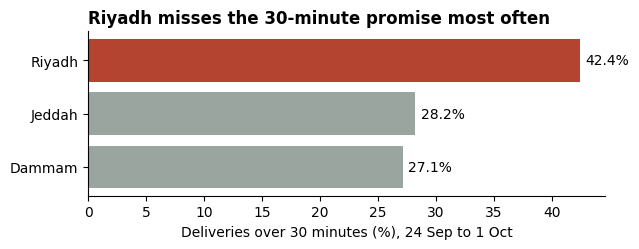

In [21]:
reset()
run_platform()
revenue = df("""SELECT round(sum(items_amount)) AS product_revenue_sar, count(*) AS delivered_orders
                FROM analyst.orders WHERE status = 'delivered'""")
ops = df("""SELECT city, sum(delivered_orders) AS delivered, sum(sla_breaches) AS missed,
                   round(100.0 * sum(sla_breaches) / sum(delivered_orders), 1) AS missed_pct
            FROM analyst.ops_daily GROUP BY city ORDER BY missed_pct DESC""")
display(revenue, ops)

fig, ax = plt.subplots(figsize=(6.5, 2.6))
order = ops.iloc[::-1]
ax.barh(order.city, order.missed_pct, color=["#9aa59f"] * (len(ops) - 1) + ["#b4432f"])
ax.set_title("Riyadh misses the 30-minute promise most often", loc="left", fontweight="bold")
ax.set_xlabel("Deliveries over 30 minutes (%), 24 Sep to 1 Oct")
ax.spines[["top", "right"]].set_visible(False)
for i, v in enumerate(order.missed_pct):
    ax.text(v + 0.5, i, f"{v}%", va="center")
plt.tight_layout()
plt.show()

**Result:** finance gets one number, 6,500,179 SAR of product revenue, under a written definition. Operations sees that Riyadh is the outlier at 42.4%, against about 28% elsewhere. This shows where to look, not why it happens.

## Limits and next steps

- **A blocked row stays in bronze.** Validate each batch before commit.
- **Full snapshots and one DuckDB writer** would break first at 100× the volume. Use change data capture, and Iceberg as the system of record.
- **Warnings wait for someone to look.** Route alerts to each owner.
- **Backups outlive an erasure.** Add a retention rule and key rotation.
- **The payments API is the course's local stand-in**, so real provider failures are untested.